# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 2.5G
-rw-r--r-- 1 csmoran03 csmoran03 357K Oct 21 14:34 Lab.7.ipynb
-rw-r--r-- 1 csmoran03 csmoran03 150K Oct 21 14:34 Lab.7.pdf
-rw-r--r-- 1 csmoran03 csmoran03 430K Oct 29 09:56 Lab.7.solution.ipynb
-rw-r--r-- 1 csmoran03 csmoran03 228M Oct 29 08:50 SUSY-small.csv
-rw-r--r-- 1 csmoran03 csmoran03 2.3G Oct 28 17:11 SUSY.csv


The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

total 2.5G
-rw-r--r-- 1 csmoran03 csmoran03 357K Oct 21 14:34 Lab.7.ipynb
-rw-r--r-- 1 csmoran03 csmoran03 150K Oct 21 14:34 Lab.7.pdf
-rw-r--r-- 1 csmoran03 csmoran03 430K Oct 29 09:56 Lab.7.solution.ipynb
-rw-r--r-- 1 csmoran03 csmoran03 228M Oct 29 08:50 SUSY-small.csv
-rw-r--r-- 1 csmoran03 csmoran03 2.3G Oct 28 17:11 SUSY.csv


We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

total 2.5G
-rw-r--r-- 1 csmoran03 csmoran03 357K Oct 21 14:34 Lab.7.ipynb
-rw-r--r-- 1 csmoran03 csmoran03 150K Oct 21 14:34 Lab.7.pdf
-rw-r--r-- 1 csmoran03 csmoran03 430K Oct 29 09:56 Lab.7.solution.ipynb
-rw-r--r-- 1 csmoran03 csmoran03 228M Nov 25 23:14 SUSY-small.csv
-rw-r--r-- 1 csmoran03 csmoran03 2.3G Oct 28 17:11 SUSY.csv


In [10]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['M_Delta_R',
 'axial_MET',
 'MT2',
 'dPhi_r_b',
 'MET_rel',
 'S_R',
 'R',
 'cos_theta_r1',
 'M_R',
 'M_TR_2']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


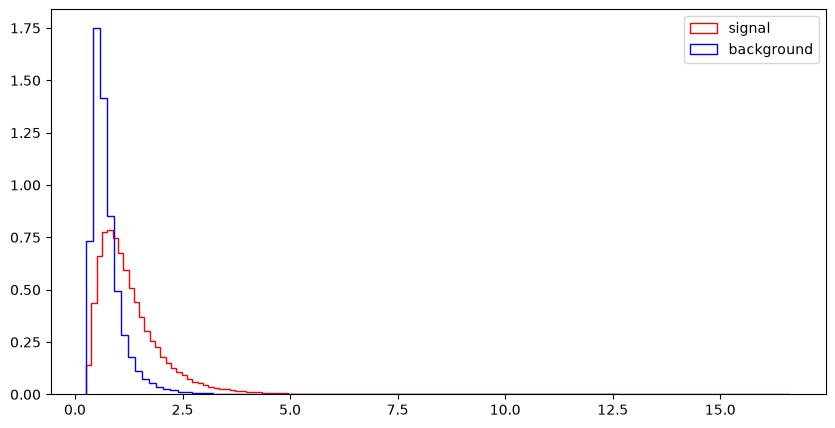

l_1_eta


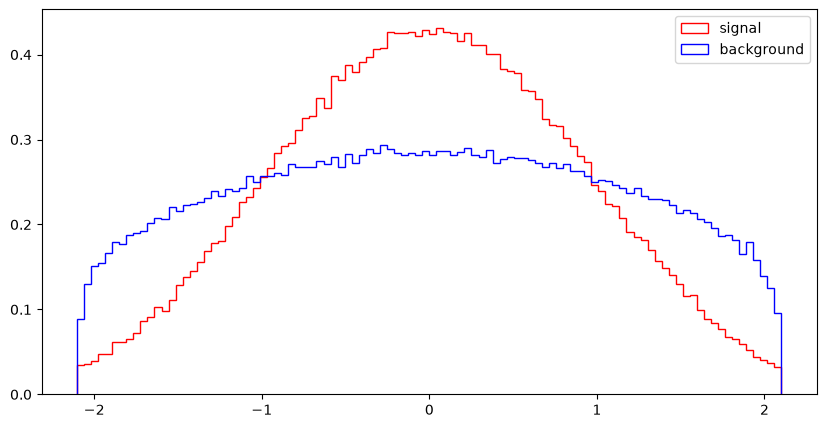

l_1_phi


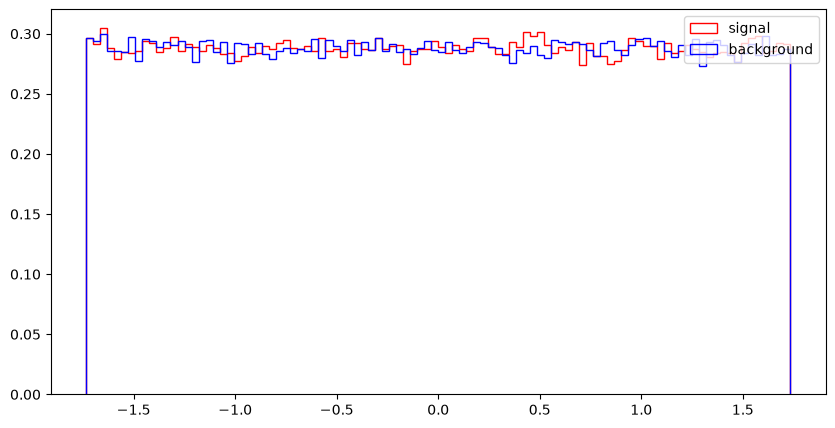

l_2_pT


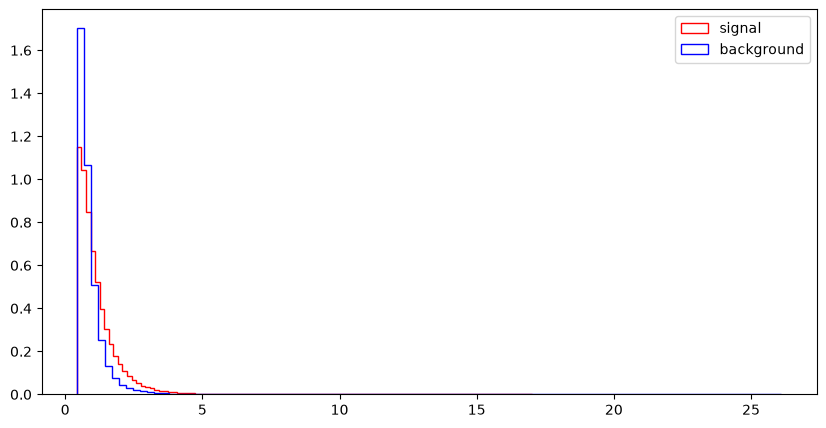

l_2_eta


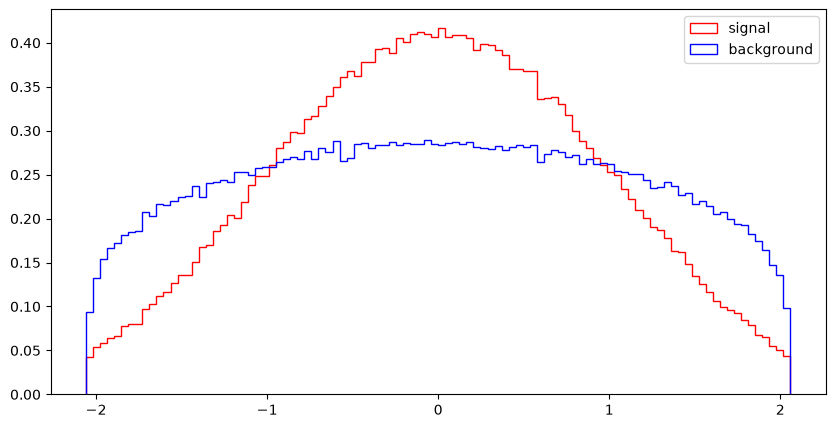

l_2_phi


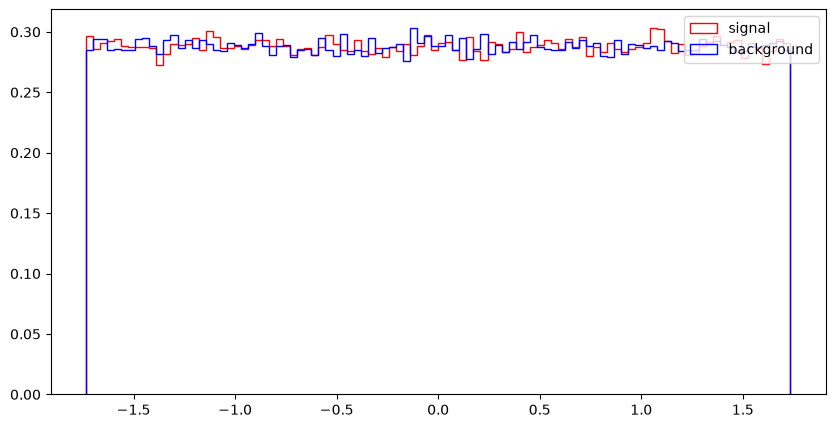

MET


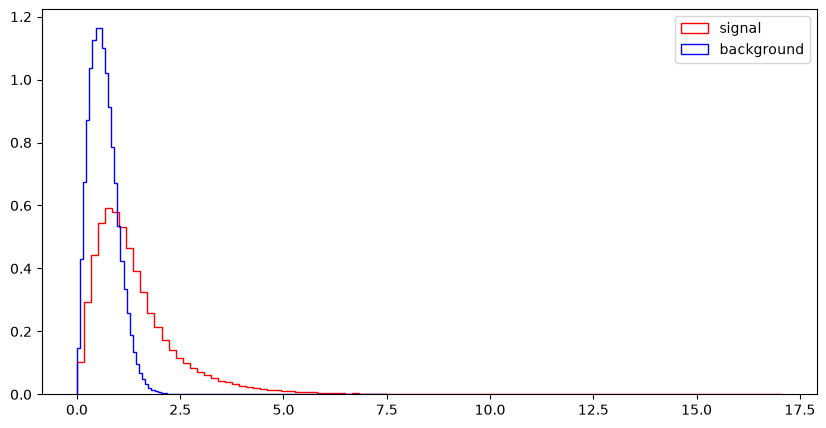

MET_phi


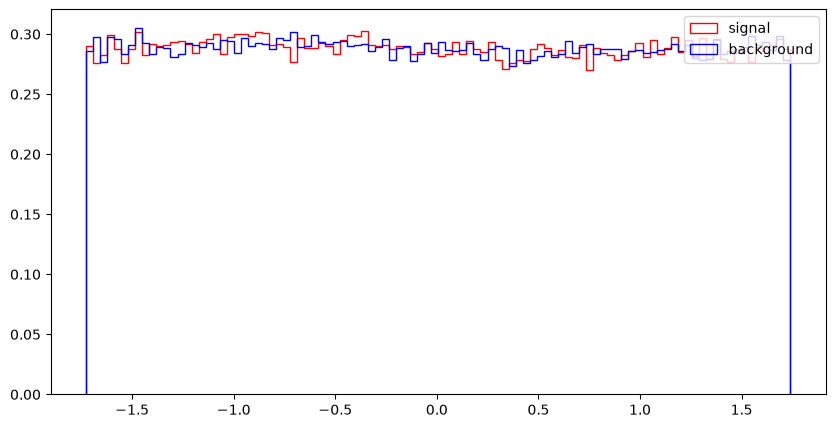

MET_rel


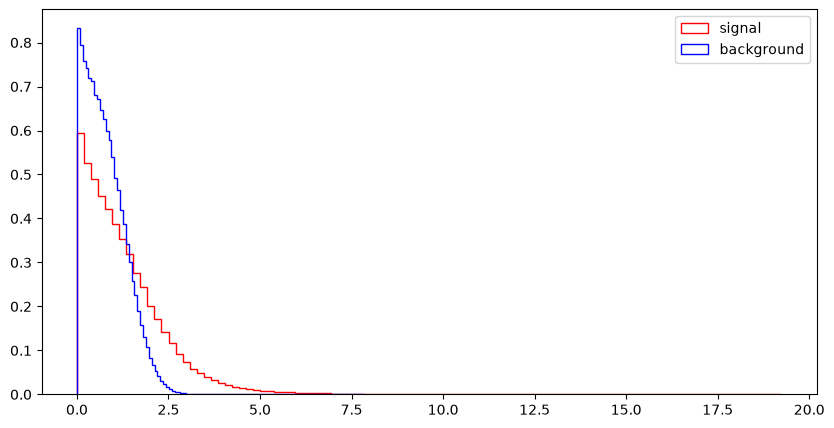

axial_MET


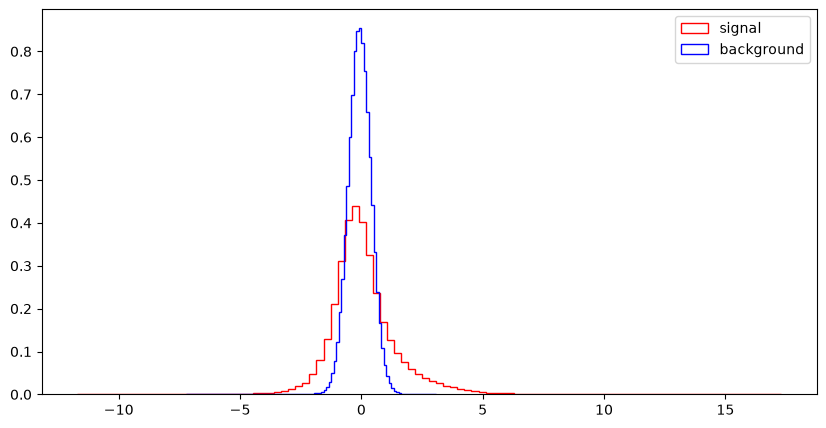

M_R


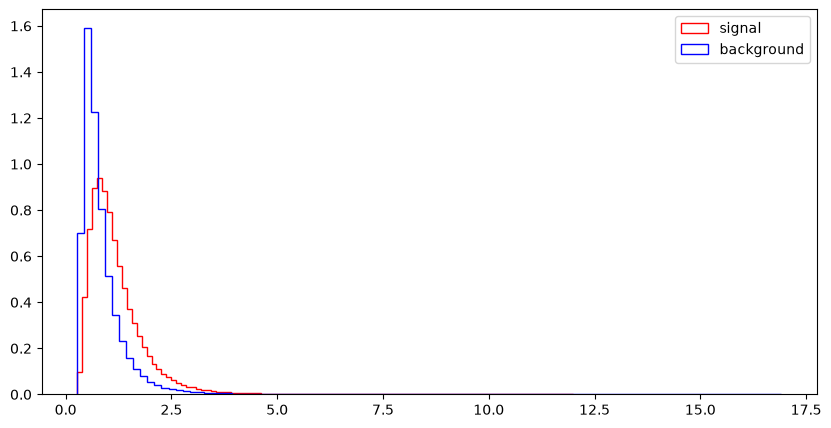

M_TR_2


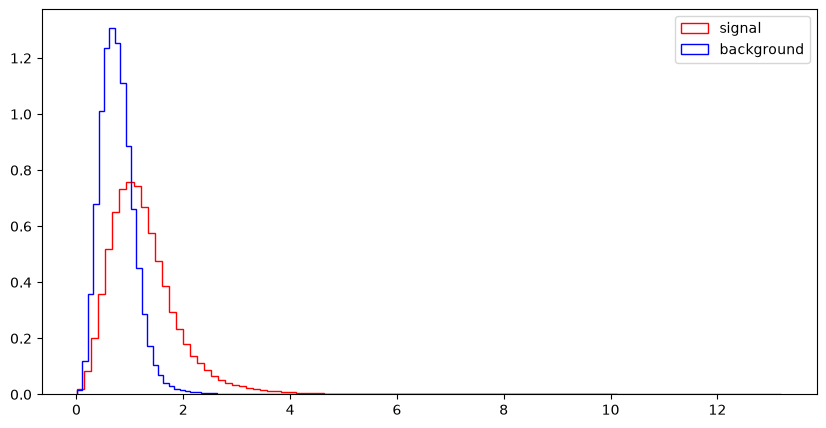

R


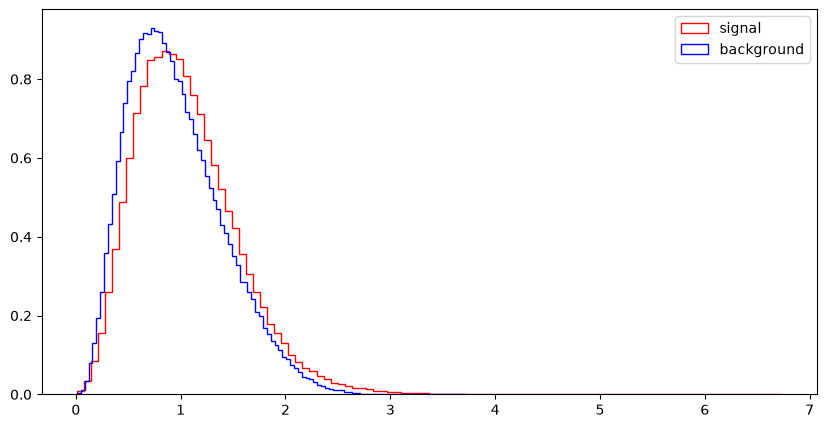

MT2


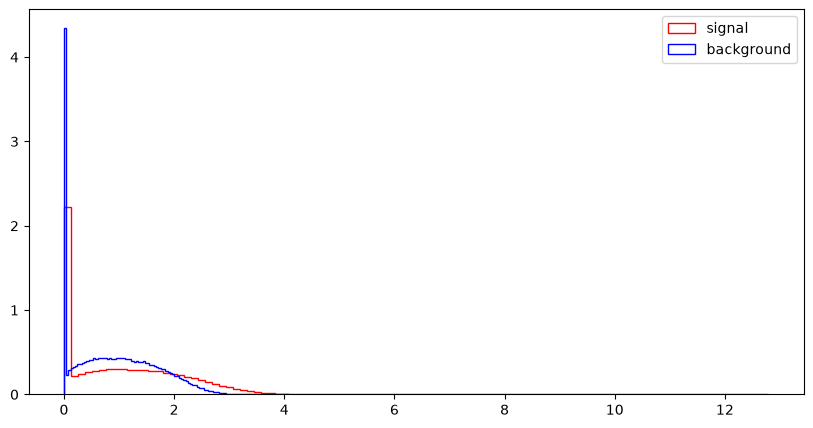

S_R


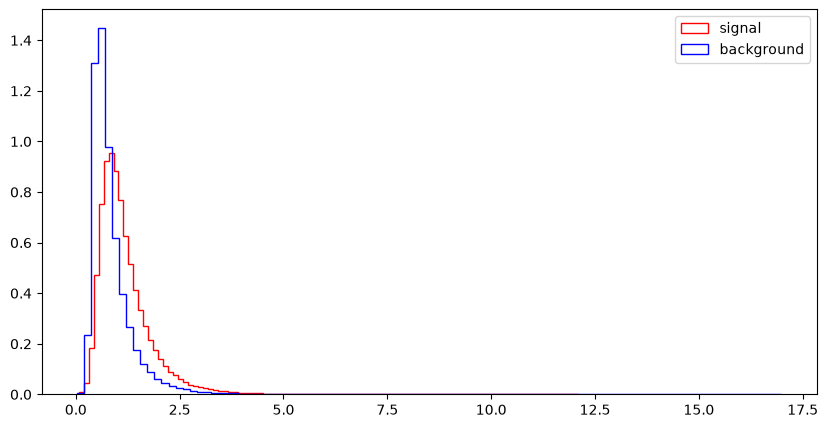

M_Delta_R


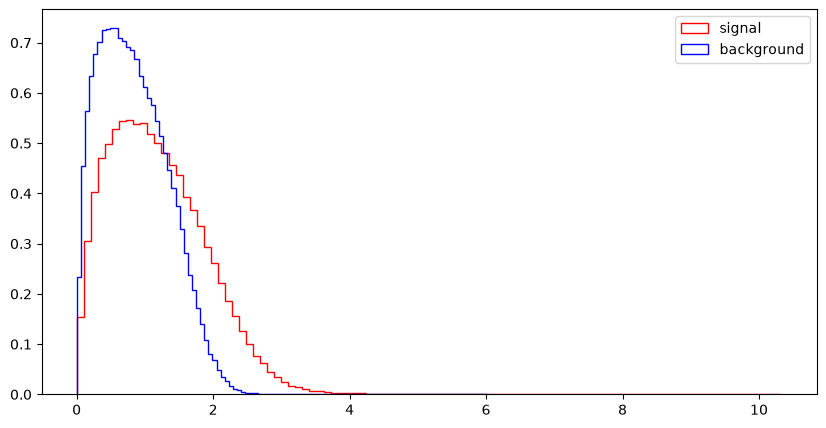

dPhi_r_b


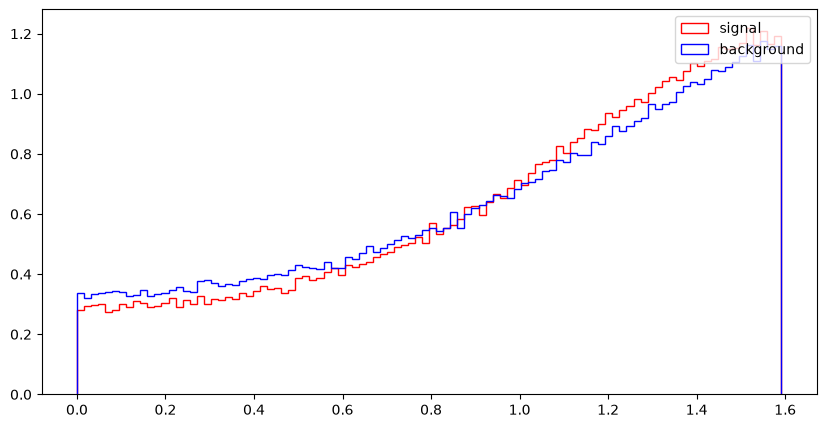

cos_theta_r1


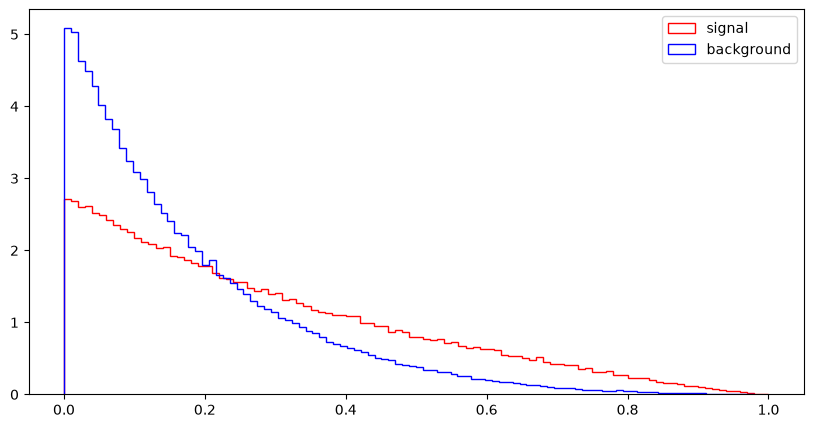

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

Generating pair plots for low-level features...


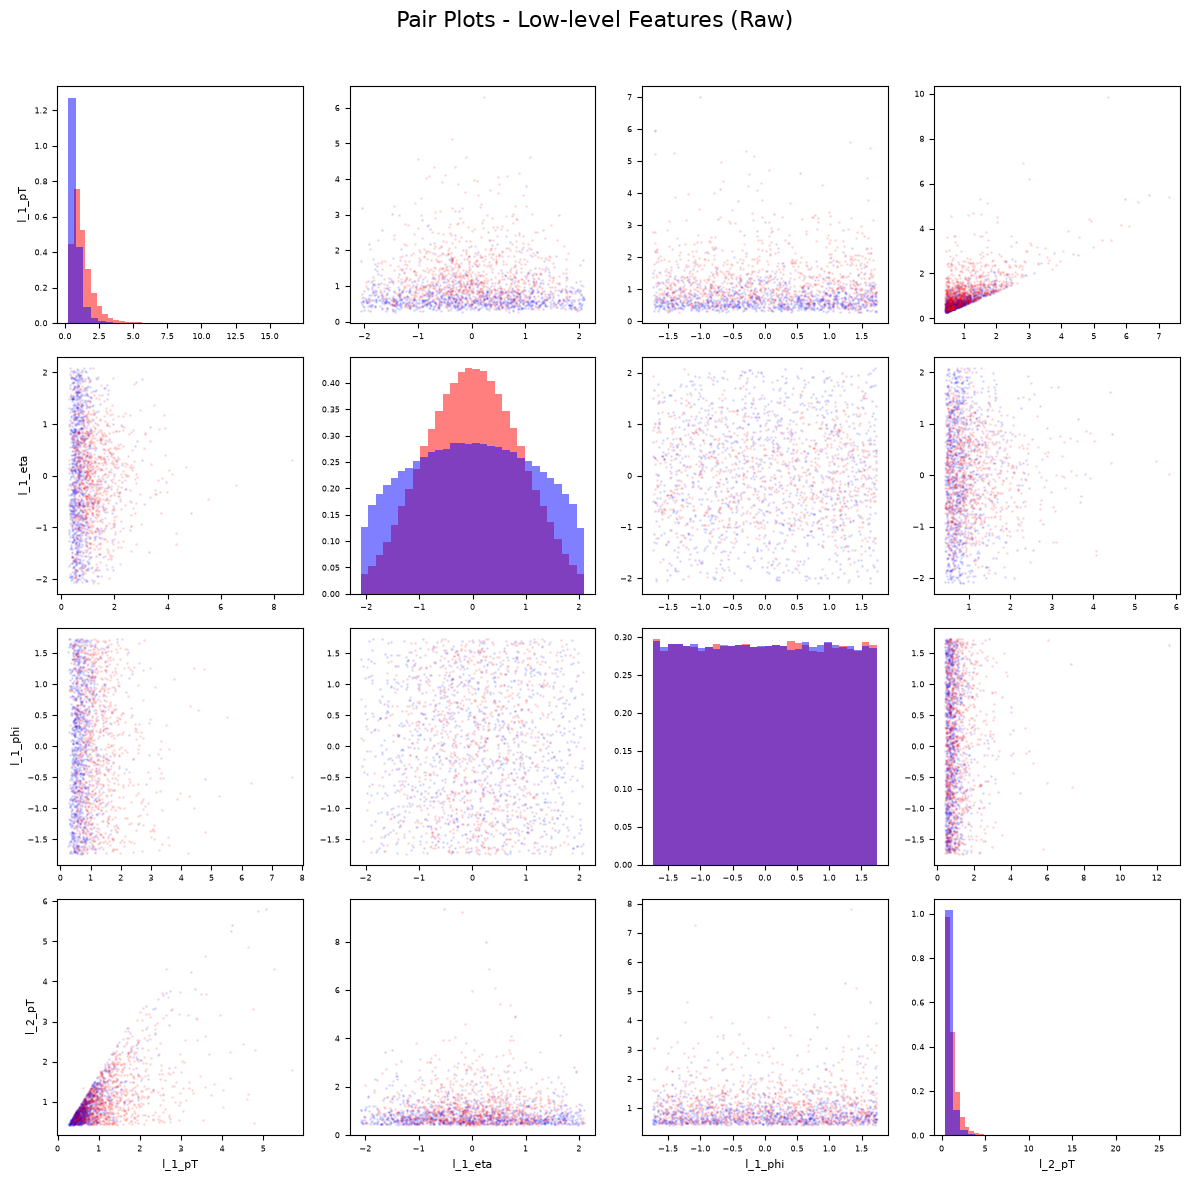

Generating pair plots for high-level features...


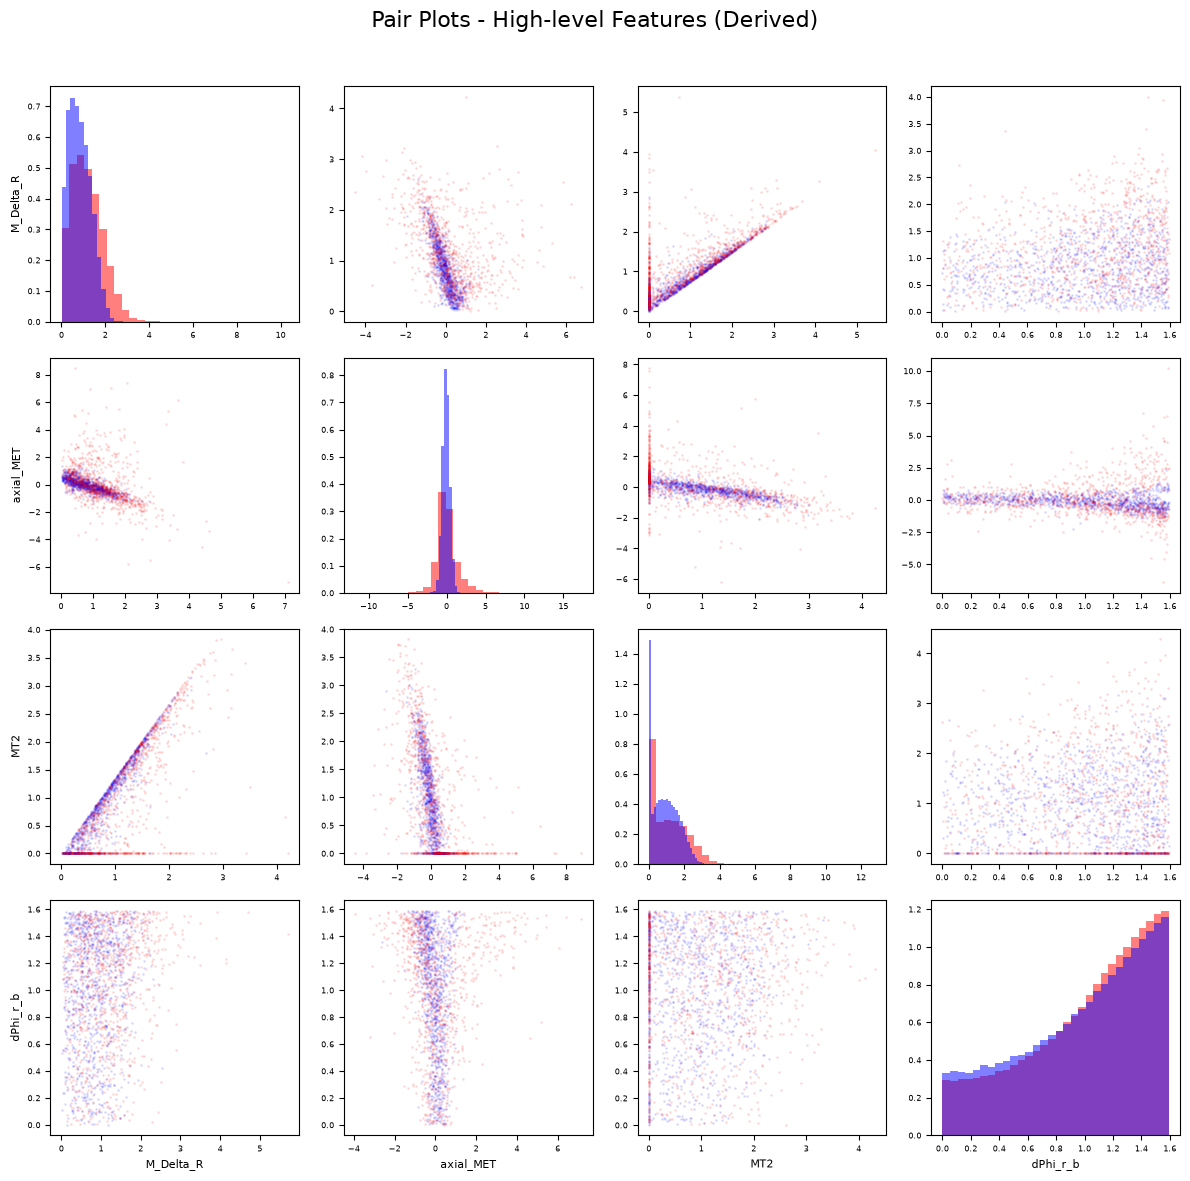

In [20]:
#Part A
def create_pair_plots(data_sig, data_bkg, features, title_suffix=""):

    n = len(features)
    fig, axes = plt.subplots(n, n, figsize=(3 * n, 3 * n))
    fig.suptitle(f"Pair Plots - {title_suffix}", fontsize=16)

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            col_x = features[j]
            col_y = features[i]

            if i == j:
                ax.hist(data_sig[col_x], bins=30, alpha=0.5, color='red', label='Signal', density=True)
                ax.hist(data_bkg[col_x], bins=30, alpha=0.5, color='blue', label='Background', density=True)
            else:
                sample_sig = data_sig.sample(min(1000, len(data_sig)))
                sample_bkg = data_bkg.sample(min(1000, len(data_bkg)))
                ax.scatter(sample_bkg[col_x], sample_bkg[col_y], color='blue', alpha=0.1, s=1, label='Bkg')
                ax.scatter(sample_sig[col_x], sample_sig[col_y], color='red', alpha=0.1, s=1, label='Sig')

            if i == n - 1:
                ax.set_xlabel(col_x, fontsize=8)
            if j == 0:
                ax.set_ylabel(col_y, fontsize=8)
            ax.tick_params(axis='both', which='major', labelsize=6)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

subset_low = RawNames[:4]
subset_high = FeatureNames[:4]

print("Generating pair plots for low-level features...")
create_pair_plots(df_sig, df_bkg, subset_low, "Low-level Features (Raw)")

print("Generating pair plots for high-level features...")
create_pair_plots(df_sig, df_bkg, subset_high, "High-level Features (Derived)")

Generating optimized pair plots for high-level features...


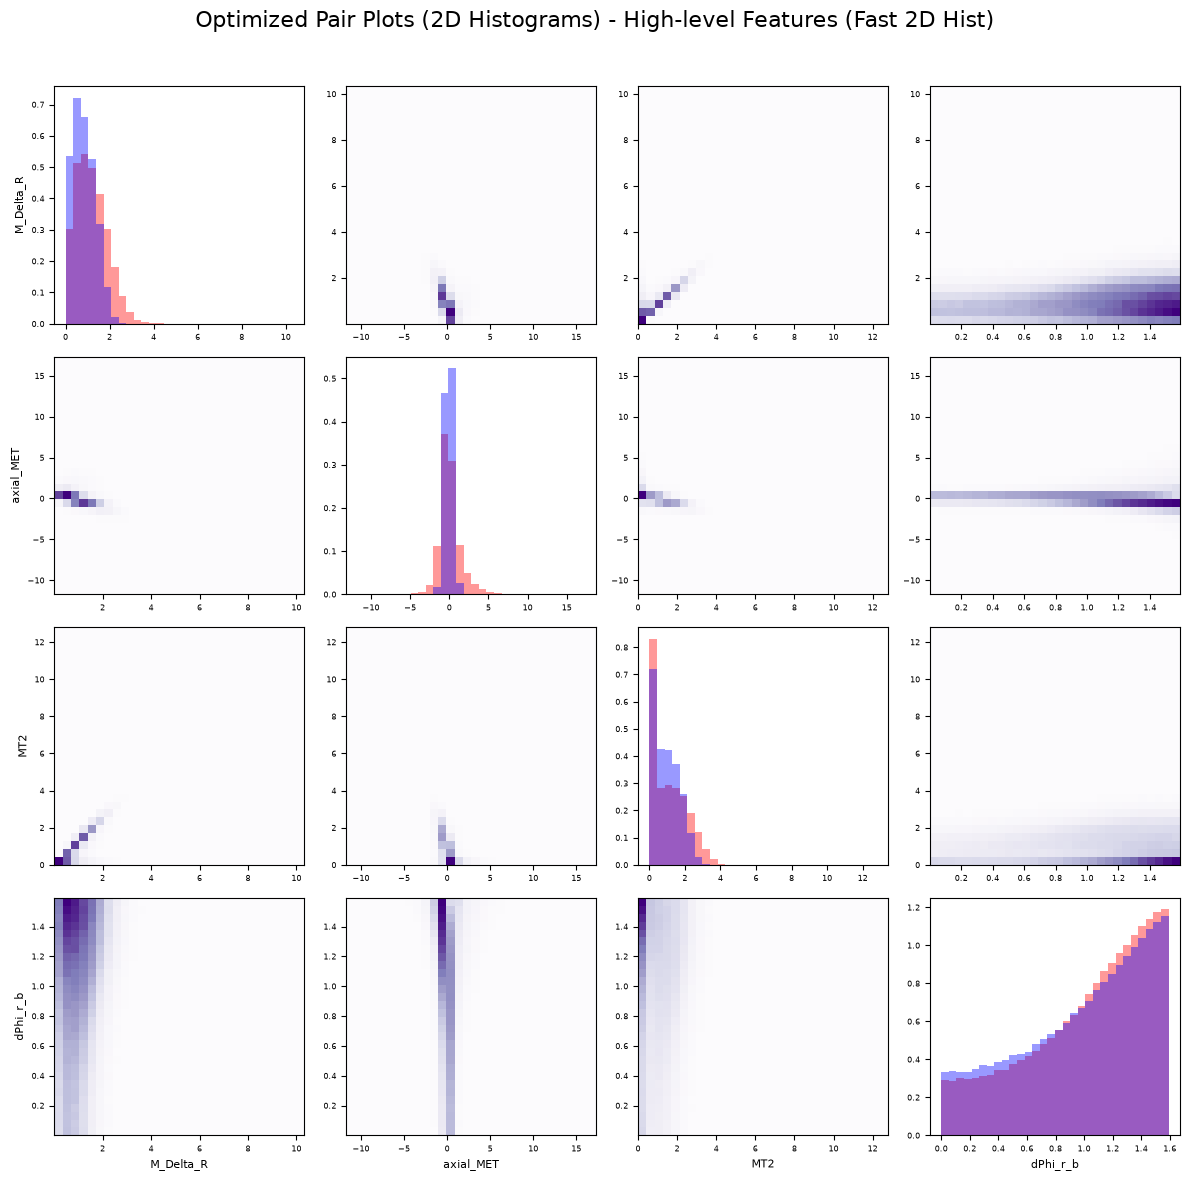

In [21]:
#Part B
def create_fast_pair_plots(data_sig, data_bkg, features, bins=30, title_suffix=""):
    n = len(features)
    fig, axes = plt.subplots(n, n, figsize=(3 * n, 3 * n))
    fig.suptitle(f"Optimized Pair Plots (2D Histograms) - {title_suffix}", fontsize=16)

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            col_x = features[j]
            col_y = features[i]

            if i == j:
                counts_sig, edges = np.histogram(data_sig[col_x], bins=bins, density=True)
                counts_bkg, _ = np.histogram(data_bkg[col_x], bins=edges, density=True)

                width = np.diff(edges)
                ax.bar(edges[:-1], counts_sig, width=width, alpha=0.4, color='red', label='Signal', align='edge')
                ax.bar(edges[:-1], counts_bkg, width=width, alpha=0.4, color='blue', label='Background', align='edge')
            else:
                ax.hist2d(df[col_x], df[col_y], bins=bins, cmap='Purples')

            if i == n - 1:
                ax.set_xlabel(col_x, fontsize=8)
            if j == 0:
                ax.set_ylabel(col_y, fontsize=8)
            ax.tick_params(axis='both', which='major', labelsize=6)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

print("Generating optimized pair plots for high-level features...")
create_fast_pair_plots(df_sig, df_bkg, subset_high, title_suffix="High-level Features (Fast 2D Hist)")

In [ ]:
# Part C
# it seems to be the M_TR_2 and the 1_1_PT.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

In [22]:
#part A
!pip install tabulate


Hint: Example code for embedding a `tabulate` table into a notebook:

In [19]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [ ]:
## Solutions to Exercise 4


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Exercise 5.1:
def get_optimal_strategy(df_sig, df_bkg, var):
    mean_sig = df_sig[var].mean()
    mean_bkg = df_bkg[var].mean()
    if mean_sig > mean_bkg:
        return ">"
    else:
        return "<"

strategies = {var: get_optimal_strategy(df_sig, df_bkg, var) for var in VarNames[1:]}
print("Optimal Selection Strategies:")
for var, strategy in strategies.items():
    print(f"  {var}: x {strategy} x_c")

Optimal Selection Strategies:
  l_1_pT: x > x_c
  l_1_eta: x > x_c
  l_1_phi: x > x_c
  l_2_pT: x > x_c
  l_2_eta: x > x_c
  l_2_phi: x > x_c
  MET: x > x_c
  MET_phi: x < x_c
  MET_rel: x > x_c
  axial_MET: x > x_c
  M_R: x > x_c
  M_TR_2: x > x_c
  R: x > x_c
  MT2: x > x_c
  S_R: x > x_c
  M_Delta_R: x > x_c
  dPhi_r_b: x > x_c
  cos_theta_r1: x > x_c


Plotting analysis for a selection of features:


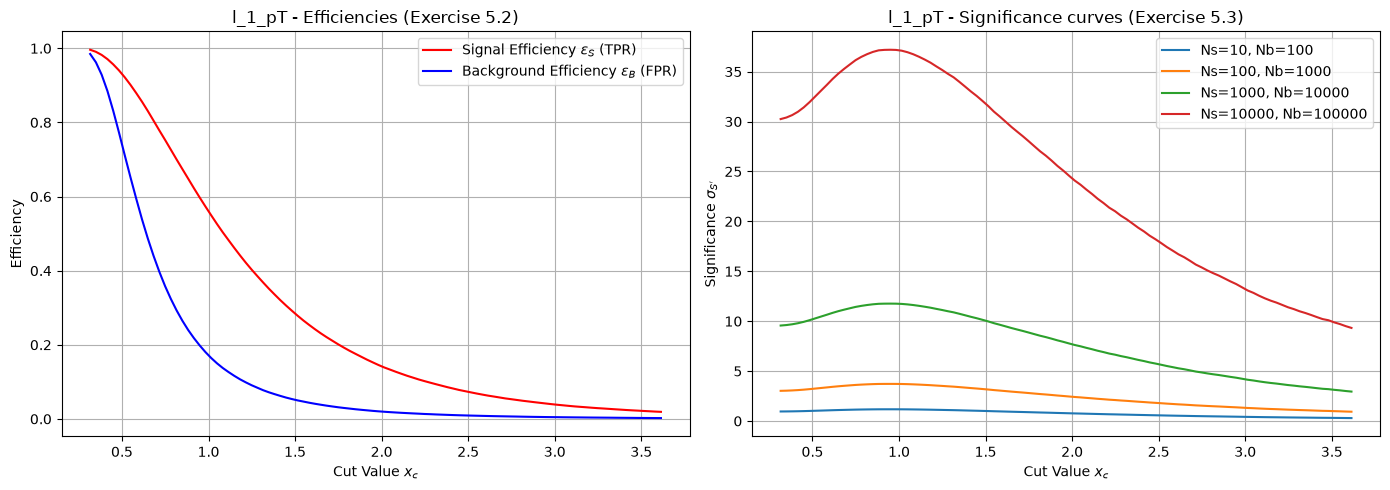

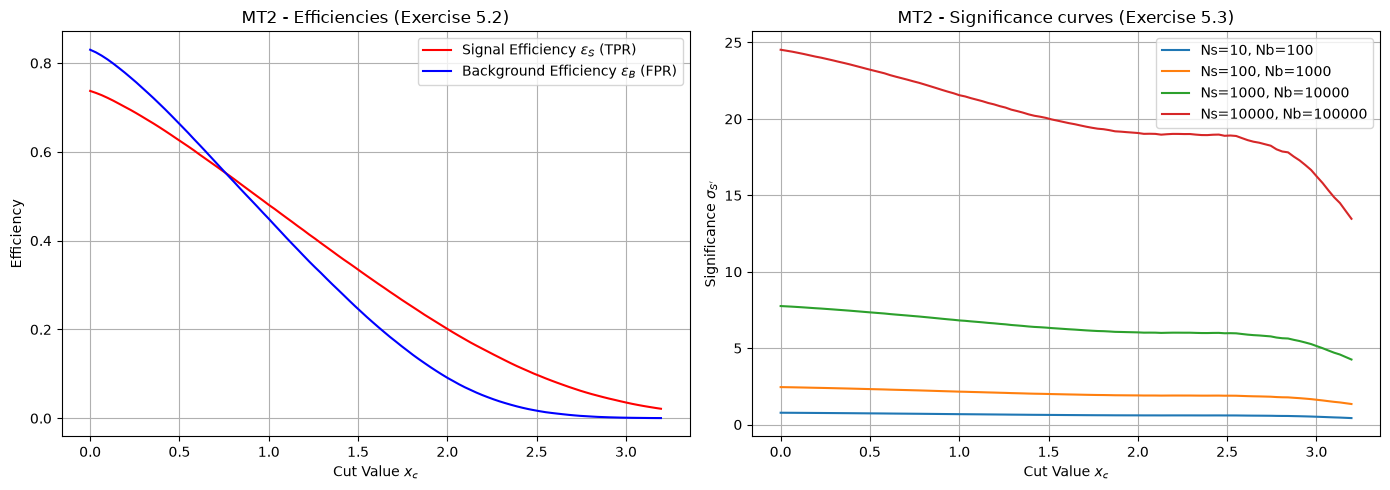

In [27]:
# Exercise 5.2 & 5.3
scenarios = [
    {"Ns": 10, "Nb": 100},
    {"Ns": 100, "Nb": 1000},
    {"Ns": 1000, "Nb": 10000},
    {"Ns": 10000, "Nb": 100000}
]

def analyze_selections(df_sig, df_bkg, variables):
    for var in variables:
        all_vals = pd.concat([df_sig[var], df_bkg[var]])
        xmin, xmax = np.percentile(all_vals, 1), np.percentile(all_vals, 99)
        x_cuts = np.linspace(xmin, xmax, 100)

        eps_S = []
        eps_B = []
        strategy = strategies[var]

        total_sig = len(df_sig)
        total_bkg = len(df_bkg)

        for xc in x_cuts:
            if strategy == ">":
                eff_s = np.sum(df_sig[var] > xc) / total_sig
                eff_b = np.sum(df_bkg[var] > xc) / total_bkg
            else:
                eff_s = np.sum(df_sig[var] < xc) / total_sig
                eff_b = np.sum(df_bkg[var] < xc) / total_bkg
            eps_S.append(eff_s)
            eps_B.append(eff_b)

        eps_S = np.array(eps_S)
        eps_B = np.array(eps_B)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].plot(x_cuts, eps_S, label=r'Signal Efficiency $\epsilon_S$ (TPR)', color='red')
        axes[0].plot(x_cuts, eps_B, label=r'Background Efficiency $\epsilon_B$ (FPR)', color='blue')
        axes[0].set_title(f"{var} - Efficiencies (Exercise 5.2)")
        axes[0].set_xlabel("Cut Value $x_c$")
        axes[0].set_ylabel("Efficiency")
        axes[0].legend()
        axes[0].grid(True)

        for s_idx, sc in enumerate(scenarios):
            Ns, Nb = sc["Ns"], sc["Nb"]
            Ns_prime = eps_S * Ns
            Nb_prime = eps_B * Nb
            denom = np.sqrt(Ns_prime + Nb_prime)
            significance = np.where(denom > 0, Ns_prime / denom, 0)

            axes[1].plot(x_cuts, significance, label=f"Ns={Ns}, Nb={Nb}")

        axes[1].set_title(f"{var} - Significance curves (Exercise 5.3)")
        axes[1].set_xlabel("Cut Value $x_c$")
        axes[1].set_ylabel(r"Significance $\sigma_{S'}$")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()

print("Plotting analysis for a selection of features:")
analyze_selections(df_sig, df_bkg, ['l_1_pT', 'MT2'])

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [28]:
import numpy as np
import pandas as pd
import tabulate
from IPython.display import HTML, display

# Exercise 6.1 & 6.2
cuts = [
    {"var": "MT2", "xc": 0.6, "strategy": ">"},
    {"var": "M_TR_2", "xc": 0.8, "strategy": ">"},
    {"var": "l_1_pT", "xc": 1.0, "strategy": ">"}
]

def run_cut_flow(df_sig, df_bkg, cuts, scenarios):
    for s_idx, sc in enumerate(scenarios):
        Ns, Nb = sc["Ns"], sc["Nb"]
        display(HTML(f"<h3>Cut-Flow Table for Scenario {s_idx+1} (Ns={Ns}, Nb={Nb})</h3>"))

        current_sig = df_sig.copy()
        current_bkg = df_bkg.copy()

        total_sig = len(df_sig)
        total_bkg = len(df_bkg)

        table_rows = []

        eps_s = 1.0
        eps_b = 1.0
        Ns_prime = Ns
        Nb_prime = Nb
        sig = Ns_prime / np.sqrt(Ns_prime + Nb_prime) if (Ns_prime + Nb_prime) > 0 else 0
        table_rows.append(["Baseline (No cuts)", f"{eps_s:.4f}", f"{eps_b:.4f}", f"{Ns_prime:.2f}", f"{Nb_prime:.2f}", f"{sig:.4f}"])

        for cut in cuts:
            var = cut["var"]
            xc = cut["xc"]
            strat = cut["strategy"]

            if strat == ">":
                current_sig = current_sig[current_sig[var] > xc]
                current_bkg = current_bkg[current_bkg[var] > xc]
            else:
                current_sig = current_sig[current_sig[var] < xc]
                current_bkg = current_bkg[current_bkg[var] < xc]

            eps_s = len(current_sig) / total_sig
            eps_b = len(current_bkg) / total_bkg

            Ns_prime = eps_s * Ns
            Nb_prime = eps_b * Nb

            denom = np.sqrt(Ns_prime + Nb_prime)
            sig = Ns_prime / denom if denom > 0 else 0

            table_rows.append([
                f"Apply {var} {strat} {xc}",
                f"{eps_s:.4f}",
                f"{eps_b:.4f}",
                f"{Ns_prime:.2f}",
                f"{Nb_prime:.2f}",
                f"{sig:.4f}"
            ])

        headers = ["Selection Step", "Signal Eff. (eps_S)", "Bkg Eff. (eps_B)", "N'_S", "N'_B", "Significance (sigma)"]
        display(HTML(tabulate.tabulate(table_rows, tablefmt='html', headers=headers)))

run_cut_flow(df_sig, df_bkg, cuts, scenarios)

Selection Step,Signal Eff. (eps_S),Bkg Eff. (eps_B),N'_S,N'_B,Significance (sigma)
Baseline (No cuts),1,1,10,100,0.9535
Apply MT2 > 0.6,0.5978,0.621,5.98,62.1,0.7246
Apply M_TR_2 > 0.8,0.5111,0.3545,5.11,35.45,0.8025
Apply l_1_pT > 1.0,0.3018,0.0869,3.02,8.69,0.8818


Selection Step,Signal Eff. (eps_S),Bkg Eff. (eps_B),N'_S,N'_B,Significance (sigma)
Baseline (No cuts),1,1,100,1000,3.0151
Apply MT2 > 0.6,0.5978,0.621,59.78,620.98,2.2912
Apply M_TR_2 > 0.8,0.5111,0.3545,51.11,354.46,2.5378
Apply l_1_pT > 1.0,0.3018,0.0869,30.18,86.95,2.7883


Selection Step,Signal Eff. (eps_S),Bkg Eff. (eps_B),N'_S,N'_B,Significance (sigma)
Baseline (No cuts),1,1,1000,10000,9.5346
Apply MT2 > 0.6,0.5978,0.621,597.82,6209.82,7.2456
Apply M_TR_2 > 0.8,0.5111,0.3545,511.08,3544.57,8.0253
Apply l_1_pT > 1.0,0.3018,0.0869,301.77,869.49,8.8175


Selection Step,Signal Eff. (eps_S),Bkg Eff. (eps_B),N'_S,N'_B,Significance (sigma)
Baseline (No cuts),1,1,10000,100000,30.1511
Apply MT2 > 0.6,0.5978,0.621,5978.19,62098.2,22.9124
Apply M_TR_2 > 0.8,0.5111,0.3545,5110.82,35445.7,25.3782
Apply l_1_pT > 1.0,0.3018,0.0869,3017.69,8694.95,27.8835


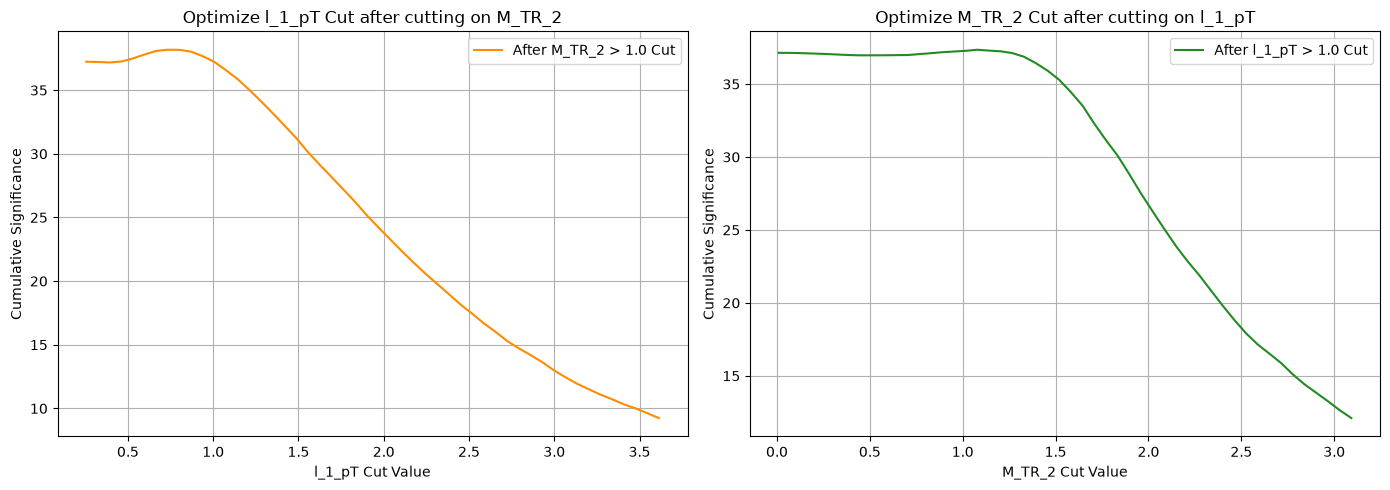

In [29]:
# Exercise 6.3
Ns, Nb = 10000, 100000

var1 = "M_TR_2"
var2 = "l_1_pT"

x_cuts_1 = np.linspace(df[var1].min(), np.percentile(df[var1], 99), 50)
x_cuts_2 = np.linspace(df[var2].min(), np.percentile(df[var2], 99), 50)

cut_val_1 = 1.0
df_sig_after1 = df_sig[df_sig[var1] > cut_val_1]
df_bkg_after1 = df_bkg[df_bkg[var1] > cut_val_1]

eps_S1_base = len(df_sig_after1) / len(df_sig)
eps_B1_base = len(df_bkg_after1) / len(df_bkg)

sigs_opt_2 = []
for xc in x_cuts_2:
    # Cumulative efficiencies
    eff_s = np.sum(df_sig_after1[var2] > xc) / len(df_sig)
    eff_b = np.sum(df_bkg_after1[var2] > xc) / len(df_bkg)

    Ns_p = eff_s * Ns
    Nb_p = eff_b * Nb
    denom = np.sqrt(Ns_p + Nb_p)
    sigs_opt_2.append(Ns_p / denom if denom > 0 else 0)

cut_val_2 = 1.0
df_sig_after2 = df_sig[df_sig[var2] > cut_val_2]
df_bkg_after2 = df_bkg[df_bkg[var2] > cut_val_2]

sigs_opt_1 = []
for xc in x_cuts_1:
    # Cumulative efficiencies
    eff_s = np.sum(df_sig_after2[var1] > xc) / len(df_sig)
    eff_b = np.sum(df_bkg_after2[var1] > xc) / len(df_bkg)

    Ns_p = eff_s * Ns
    Nb_p = eff_b * Nb
    denom = np.sqrt(Ns_p + Nb_p)
    sigs_opt_1.append(Ns_p / denom if denom > 0 else 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(x_cuts_2, sigs_opt_2, color='darkorange', label="After M_TR_2 > 1.0 Cut")
axes[0].set_title(f"Optimize {var2} Cut after cutting on {var1}")
axes[0].set_xlabel(f"{var2} Cut Value")
axes[0].set_ylabel("Cumulative Significance")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(x_cuts_1, sigs_opt_1, color='forestgreen', label="After l_1_pT > 1.0 Cut")
axes[1].set_title(f"Optimize {var1} Cut after cutting on {var2}")
axes[1].set_xlabel(f"{var1} Cut Value")
axes[1].set_ylabel("Cumulative Significance")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



Generating ROC curves for top 3 variables...


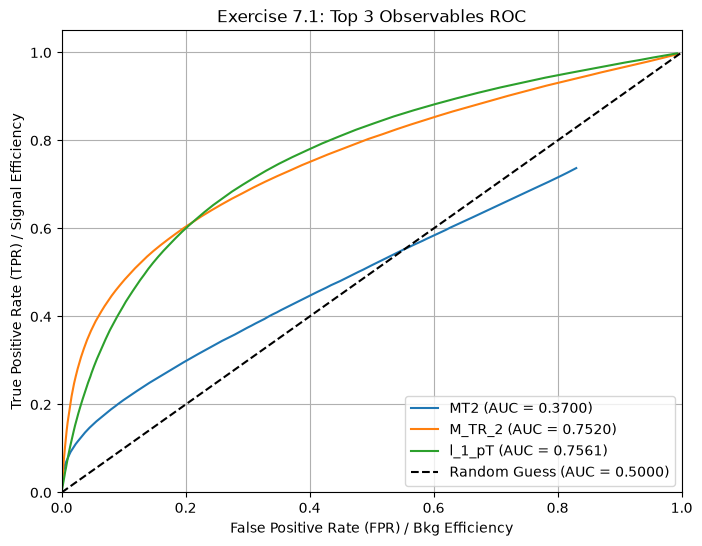

In [30]:
#Exercises 7.1 & 7.2

from scipy.integrate import simpson

def get_roc_points(df_sig, df_bkg, var, strategy):
    all_vals = pd.concat([df_sig[var], df_bkg[var]])
    xmin, xmax = np.percentile(all_vals, 0.5), np.percentile(all_vals, 99.5)
    x_cuts = np.linspace(xmin, xmax, 200)

    tpr = []
    fpr = []
    total_sig = len(df_sig)
    total_bkg = len(df_bkg)

    for xc in x_cuts:
        if strategy == ">":
            eff_s = np.sum(df_sig[var] > xc) / total_sig
            eff_b = np.sum(df_bkg[var] > xc) / total_bkg
        else:
            eff_s = np.sum(df_sig[var] < xc) / total_sig
            eff_b = np.sum(df_bkg[var] < xc) / total_bkg
        tpr.append(eff_s)
        fpr.append(eff_b)

    sorted_indices = np.argsort(fpr)
    fpr_sorted = np.array(fpr)[sorted_indices]
    tpr_sorted = np.array(tpr)[sorted_indices]
    auc_val = simpson(tpr_sorted, x=fpr_sorted)
    return fpr_sorted, tpr_sorted, auc_val

def plot_roc_curves(df_sig, df_bkg, variables, strategies, title="Receiver Operating Characteristic (ROC) Curves"):
    plt.figure(figsize=(8, 6))

    for var in variables:
        strat = strategies[var]
        fpr, tpr, auc_val = get_roc_points(df_sig, df_bkg, var, strat)
        plt.plot(fpr, tpr, label=f"{var} (AUC = {auc_val:.4f})")

    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.5000)")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (FPR) / Bkg Efficiency')
    plt.ylabel('True Positive Rate (TPR) / Signal Efficiency')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

top_3_vars = ["MT2", "M_TR_2", "l_1_pT"]
print("Generating ROC curves for top 3 variables...")
plot_roc_curves(df_sig, df_bkg, top_3_vars, strategies, title="Exercise 7.1: Top 3 Observables ROC")

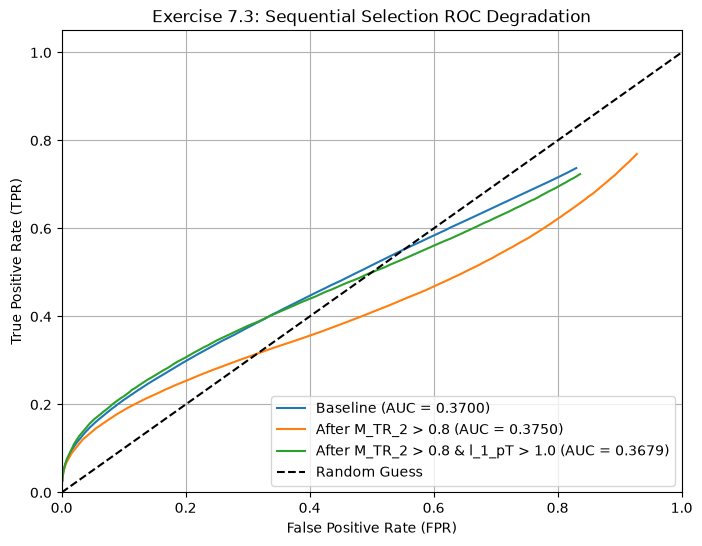

In [31]:
# Exercise 7.3
var_to_test = "MT2"

plt.figure(figsize=(8, 6))

fpr_0, tpr_0, auc_0 = get_roc_points(df_sig, df_bkg, var_to_test, strategies[var_to_test])
plt.plot(fpr_0, tpr_0, label=f"Baseline (AUC = {auc_0:.4f})")

sig_c1 = df_sig[df_sig["M_TR_2"] > 0.8]
bkg_c1 = df_bkg[df_bkg["M_TR_2"] > 0.8]
fpr_1, tpr_1, auc_1 = get_roc_points(sig_c1, bkg_c1, var_to_test, strategies[var_to_test])
plt.plot(fpr_1, tpr_1, label=f"After M_TR_2 > 0.8 (AUC = {auc_1:.4f})")

sig_c2 = sig_c1[sig_c1["l_1_pT"] > 1.0]
bkg_c2 = bkg_c1[bkg_c1["l_1_pT"] > 1.0]
fpr_2, tpr_2, auc_2 = get_roc_points(sig_c2, bkg_c2, var_to_test, strategies[var_to_test])
plt.plot(fpr_2, tpr_2, label=f"After M_TR_2 > 0.8 & l_1_pT > 1.0 (AUC = {auc_2:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title("Exercise 7.3: Sequential Selection ROC Degradation")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

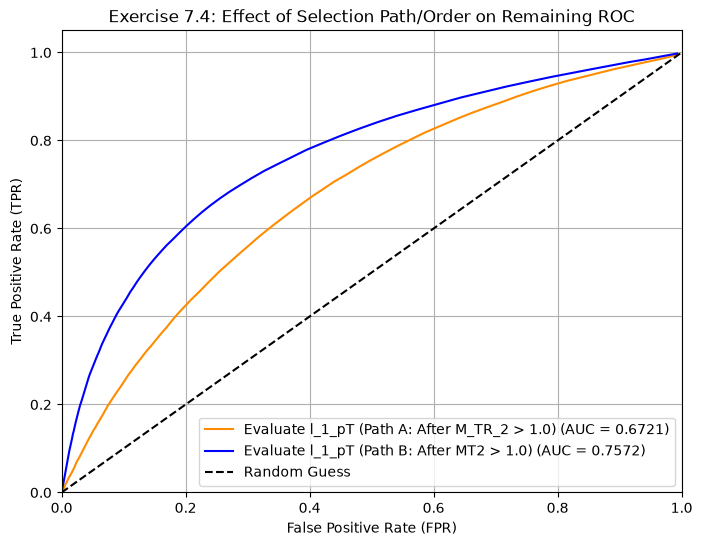

In [32]:
# Exercise 7.4
sig_path_A = df_sig[df_sig["M_TR_2"] > 1.0]
bkg_path_A = df_bkg[df_bkg["M_TR_2"] > 1.0]

sig_path_B = df_sig[df_sig["MT2"] > 1.0]
bkg_path_B = df_bkg[df_bkg["MT2"] > 1.0]

plt.figure(figsize=(8, 6))

fpr_A, tpr_A, auc_A = get_roc_points(sig_path_A, bkg_path_A, "l_1_pT", strategies["l_1_pT"])
fpr_B, tpr_B, auc_B = get_roc_points(sig_path_B, bkg_path_B, "l_1_pT", strategies["l_1_pT"])

plt.plot(fpr_A, tpr_A, label=f"Evaluate l_1_pT (Path A: After M_TR_2 > 1.0) (AUC = {auc_A:.4f})", color='darkorange')
plt.plot(fpr_B, tpr_B, label=f"Evaluate l_1_pT (Path B: After MT2 > 1.0) (AUC = {auc_B:.4f})", color='blue')

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title("Exercise 7.4: Effect of Selection Path/Order on Remaining ROC")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Exercise 8.3 & 8.4: Plot ROC curve for F_n and compute maximum significance for all scenarios
all_proj = np.concatenate([F_sig, F_bkg])
xmin, xmax = np.percentile(all_proj, 0.2), np.percentile(all_proj, 99.8)
x_cuts_F = np.linspace(xmin, xmax, 400)

tpr_F = np.mean(F_sig[:, None] > x_cuts_F[None, :], axis=0)
fpr_F = np.mean(F_bkg[:, None] > x_cuts_F[None, :], axis=0)

sorted_idx = np.argsort(fpr_F)
fpr_sorted = fpr_F[sorted_idx]
tpr_sorted = tpr_F[sorted_idx]
unique_fpr, unique_idx = np.unique(fpr_sorted, return_index=True)
auc_F = simpson(tpr_sorted[unique_idx], x=unique_fpr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)
colors = plt.cm.tab10.colors

\ax1.plot(
    fpr_sorted,
    tpr_sorted,
    color="#5e3c99",
    linewidth=2.5,
    label=f"Fisher Linear Discriminant (AUC = {auc_F:.4f})",
)
ax1.fill_between(fpr_sorted, tpr_sorted, color="#5e3c99", alpha=0.12)
ax1.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1.2, label="Random Guess (AUC = 0.5000)")

ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.03])
ax1.set_xlabel("False Positive Rate (Background Efficiency)", fontsize=11)
ax1.set_ylabel("True Positive Rate (Signal Efficiency)", fontsize=11)
ax1.set_title("Exercise 8.3: Fisher Discriminant $F_n$ ROC Curve", fontsize=13, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

\print("Exercise 8.4: Maximal Significance Obtainable via Fisher Discriminant:\n")

for idx, sc in enumerate(scenarios):
    Ns, Nb = sc["Ns"], sc["Nb"]
    color = colors[idx % len(colors)]

    Ns_prime = tpr_F * Ns
    Nb_prime = fpr_F * Nb
    denom = np.sqrt(Ns_prime + Nb_prime)
    sigs = np.where(denom > 0, Ns_prime / denom, 0.0)

    max_sig_idx = np.argmax(sigs)
    max_sig_val = sigs[max_sig_idx]
    opt_cut = x_cuts_F[max_sig_idx]
    opt_tpr = tpr_F[max_sig_idx]
    opt_fpr = fpr_F[max_sig_idx]

    label_str = f"Scenario {idx+1} ($N_s={Ns:,}, N_b={Nb:,}$) | Max $Z={max_sig_val:.2f}$"
    ax2.plot(x_cuts_F, sigs, color=color, linewidth=2.0, label=label_str)
    ax2.scatter([opt_cut], [max_sig_val], color=color, s=55, zorder=5, edgecolor="black")

    ax1.scatter(
        [opt_fpr],
        [opt_tpr],
        color=color,
        s=65,
        zorder=5,
        edgecolor="black",
        label=f"Opt. Scen. {idx+1} (Cut={opt_cut:.3f})",
    )

    print(f"Scenario {idx+1} (Ns={Ns}, Nb={Nb}):")
    print(f"  Max Significance = {max_sig_val:.4f} at F_n cut = {opt_cut:.5f}")
    print(f"  Signal Efficiency = {opt_tpr:.4f}, Background Efficiency = {opt_fpr:.4f}\n")

ax1.legend(loc="lower right", fontsize=9.5, frameon=True)

ax2.set_xlabel("Fisher Discriminant Threshold ($F_n$ Cut)", fontsize=11)
ax2.set_ylabel(r"Significance ($S / \sqrt{S + B}$)", fontsize=11)
ax2.set_title("Exercise 8.4: Signal Significance vs. $F_n$ Cut", fontsize=13, fontweight="bold")
ax2.legend(loc="best", fontsize=9.5, frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

SyntaxError: unexpected character after line continuation character (664254367.py, line 22)